# 4 Node2Vec Graph Representation Learning

## Research Objective

Can random-walk-based graph embeddings identify proteins
structurally associated with HLJ1 that are overlooked by
conventional network-theoretic methods?

### Primary Network

- Organism: Saccharomyces cerevisiae
- Dataset: STRING v12.0
- Layer: Functional associations
- Confidence threshold: 700
- Anchor protein: HLJ1 (4932.YMR161W)

### Methodology

1. Construct the HLJ1-associated connected component.
2. Generate biased random walks using Node2Vec.
3. Learn protein embeddings through Skip-gram.
4. Rank proteins using embedding similarity to HLJ1.
5. Compare against conventional graph algorithms.
6. Evaluate parameter sensitivity and ranking stability.
7. Investigate biological relevance of candidate proteins.

### Mathematical Setup

Let $G = (V, E, w)$ be the weighted PPI network.

Node2Vec learns an embedding function

$$
\mathbf{f}: V \rightarrow \mathbb{R}^d.
$$

For each protein v, its representation is

$$
\mathbf{z}_v = \mathbf{f}(v).
$$

The primary downstream objective is to identify proteins with
high embedding similarity to HLJ1.

In [1]:
from pathlib import Path
import hashlib
import json
import math

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from IPython.display import display

# -------------------------------------------------------
# 1. Paths
# -------------------------------------------------------

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

PROCESSED = ROOT / "data" / "processed" / "string_v12_0"
META = ROOT / "data" / "metadata"

OUTPUT = ROOT / "outputs" / "notebook_04"
FIGURES = ROOT / "figures"

OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------
# 2. Load frozen design
# -------------------------------------------------------

design = json.loads(
    (META / "string_analysis_design_v12_0.json").read_text()
)

baseline_record = json.loads(
    (ROOT / "outputs" / "notebook_02" / "run_record.json").read_text()
)

HLJ1_ID = design["hlj1_string_id"]
THRESHOLD = design["primary_score_threshold"]

assert THRESHOLD == 700
assert HLJ1_ID == "4932.YMR161W"

# -------------------------------------------------------
# 3. Load existing data
# -------------------------------------------------------

id_map = pd.read_csv(
    PROCESSED / "string_id_to_orf.csv",
    dtype=str
).fillna("")

edges = pd.read_csv(
    PROCESSED / "functional_edges_score_ge_400.csv.gz",
    usecols=["u", "v", "combined_score"]
)

baseline = pd.read_csv(
    ROOT / "outputs" / "notebook_02"
    / "protein_baseline_features_functional_700.csv"
)

# -------------------------------------------------------
# 4. Verify frozen processed input
# -------------------------------------------------------

def sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()


edges_path = PROCESSED / "functional_edges_score_ge_400.csv.gz"

assert sha256(edges_path) == baseline_record["functional_processed_sha256"]

# -------------------------------------------------------
# 5. Construct primary graph
# -------------------------------------------------------

selected = edges.loc[
    edges["combined_score"] >= THRESHOLD,
    ["u", "v", "combined_score"]
]

assert not selected[["u", "v"]].duplicated().any()
assert not (selected["u"] == selected["v"]).any()

G = nx.Graph()

G.add_nodes_from(id_map["string_protein_id"])

G.add_edges_from(
    (
        u,
        v,
        {
            "confidence": score / 1000,
            "length": -math.log(score / 1000)
        }
    )
    for u, v, score in selected.itertuples(
        index=False,
        name=None
    )
)

# -------------------------------------------------------
# 6. Extract HLJ1 connected component
# -------------------------------------------------------

assert HLJ1_ID in G

component_nodes = nx.node_connected_component(
    G, HLJ1_ID
)

G_hlj1 = G.subgraph(component_nodes).copy()

# -------------------------------------------------------
# 7. Validate
# -------------------------------------------------------

assert G.number_of_nodes() == 6600
assert G.number_of_edges() == 104188

assert G.degree(HLJ1_ID) == 25

assert G_hlj1.number_of_nodes() == 5716
assert G_hlj1.number_of_edges() == 104138

assert nx.is_connected(G_hlj1)

# Confirm all predefined ERAD reference proteins are present
seed_ids = {
    "4932." + orf
    for orf in design["core_seed_orfs"]
}

assert seed_ids.issubset(G_hlj1.nodes())

print("Network successfully validated!")
print(f"Full network: {G.number_of_nodes():,} nodes")
print(f"Full network: {G.number_of_edges():,} edges")

print(
    f"HLJ1 component: "
    f"{G_hlj1.number_of_nodes():,} nodes, "
    f"{G_hlj1.number_of_edges():,} edges"
)

print(f"HLJ1 degree: {G_hlj1.degree(HLJ1_ID)}")

Network successfully validated!
Full network: 6,600 nodes
Full network: 104,188 edges
HLJ1 component: 5,716 nodes, 104,138 edges
HLJ1 degree: 25


In [2]:
import numpy as np


def node2vec_transition_probs(
    G: nx.Graph,
    previous: str | None,
    current: str,
    p: float = 1.0,
    q: float = 1.0,
):
    """
    Compute Node2Vec transition probabilities.

    Parameters
    ----------
    G : nx.Graph
        Weighted PPI network.
    previous : str or None
        Previous node. None for the first step.
    current : str
        Current node.
    p : float
        Return parameter.
    q : float
        In-out parameter.

    Returns
    -------
    neighbors : list
        Possible next nodes.
    probabilities : np.ndarray
        Normalised transition probabilities.
    """

    if p <= 0 or q <= 0:
        raise ValueError("p and q must be positive.")

    neighbors = list(G.neighbors(current))

    if not neighbors:
        raise ValueError("Current node has no neighbours.")

    unnormalised = []

    for nxt in neighbors:

        # First step: ordinary weighted random walk
        if previous is None:
            bias = 1.0

        # Case 1: return to previous node
        elif nxt == previous:
            bias = 1.0 / p

        # Case 2: previous and next are connected
        elif G.has_edge(previous, nxt):
            bias = 1.0

        # Case 3: move outward
        else:
            bias = 1.0 / q

        weight = G[current][nxt]["confidence"]

        unnormalised.append(bias * weight)

    unnormalised = np.asarray(
        unnormalised,
        dtype=float
    )

    if (
        not np.isfinite(unnormalised).all()
        or np.any(unnormalised <= 0)
    ):
        raise ValueError("Transition weights must be finite and positive.")

    probabilities = unnormalised / unnormalised.sum()

    return neighbors, probabilities

In [3]:
# Construct toy graph
G_test = nx.Graph()

G_test.add_edges_from(
    [
        ("U", "V", {"confidence": 1.0}),
        ("U", "A", {"confidence": 1.0}),
        ("V", "A", {"confidence": 1.0}),
        ("V", "B", {"confidence": 1.0}),
    ]
)

neighbors, probs = node2vec_transition_probs(
    G_test,
    previous="U",
    current="V",
    p=2,
    q=0.5,
)

result = dict(zip(neighbors, probs))

print("Transition probabilities:")

for node, prob in result.items():
    print(f"P({node}) = {prob:.4f}")

# Test 1: probabilities sum to 1
assert np.isclose(sum(probs), 1.0)

# Test 2: expected Node2Vec probabilities
assert np.isclose(result["U"], 1 / 7)
assert np.isclose(result["A"], 2 / 7)
assert np.isclose(result["B"], 4 / 7)

# Test 3: p = q = 1 gives standard weighted walk
neighbors_uniform, probs_uniform = node2vec_transition_probs(
    G_test,
    previous="U",
    current="V",
    p=1,
    q=1,
)

assert np.allclose(
    probs_uniform,
    np.ones(3) / 3
)

print("\nAll transition probability tests passed!")

Transition probabilities:
P(U) = 0.1429
P(A) = 0.2857
P(B) = 0.5714

All transition probability tests passed!


In [4]:
def node2vec_walk(
    G: nx.Graph,
    start_node: str,
    walk_length: int,
    p: float,
    q: float,
    rng: np.random.Generator,
) -> list[str]:
    """
    Generate one Node2Vec biased random walk.

    walk_length is the number of nodes in the sequence,
    including the starting node.
    """

    if walk_length < 1:
        raise ValueError("walk_length must be >= 1.")

    if start_node not in G:
        raise ValueError("Start node is not in the graph.")

    walk = [start_node]

    while len(walk) < walk_length:

        current = walk[-1]

        previous = (
            walk[-2]
            if len(walk) >= 2
            else None
        )

        if G.degree(current) == 0:
            break

        neighbors, probabilities = node2vec_transition_probs(
            G,
            previous=previous,
            current=current,
            p=p,
            q=q,
        )

        next_index = rng.choice(
            len(neighbors),
            p=probabilities
        )

        next_node = neighbors[next_index]

        walk.append(next_node)

    return walk

In [5]:
RANDOM_SEED = 3888

rng = np.random.default_rng(RANDOM_SEED)

walk = node2vec_walk(
    G=G_hlj1,
    start_node=HLJ1_ID,
    walk_length=20,
    p=1.0,
    q=1.0,
    rng=rng,
)

# Convert STRING IDs to ORF names
orf_map = dict(
    zip(
        id_map["string_protein_id"],
        id_map["orf"]
    )
)

walk_orfs = [
    orf_map.get(node, node)
    for node in walk
]

print("Node2Vec walk starting from HLJ1:\n")

print(" → ".join(walk_orfs))

# Verify every consecutive pair is connected
assert all(
    G_hlj1.has_edge(u, v)
    for u, v in zip(walk[:-1], walk[1:])
)

assert len(walk) == 20

print("\nRandom walk validation passed!")

Node2Vec walk starting from HLJ1:

YMR161W → YPL240C → YCR027C → YJR066W → YDR062W → YGR218W → YKL205W → YGR264C → YER087W → YOL033W → YPL093W → YDR087C → YKL009W → YDR292C → YLR344W → YDR172W → YLR344W → YGL195W → YDL184C → YLR029C

Random walk validation passed!


In [6]:
def generate_walk_corpus(
    G: nx.Graph,
    num_walks: int,
    walk_length: int,
    p: float = 1.0,
    q: float = 1.0,
    seed: int = 3888,
) -> list[list[str]]:
    """
    Generate a Node2Vec random-walk corpus.

    Each node is used as the starting point
    num_walks times.
    """

    rng = np.random.default_rng(seed)

    nodes = sorted(G.nodes())
    walks = []

    for _ in range(num_walks):

        # Shuffle starting-node order each round
        order = rng.permutation(len(nodes))

        for idx in order:

            start = nodes[idx]

            walk = node2vec_walk(
                G=G,
                start_node=start,
                walk_length=walk_length,
                p=p,
                q=q,
                rng=rng,
            )

            walks.append(walk)

    return walks

In [7]:
# Small-scale experiment
NUM_WALKS = 2
WALK_LENGTH = 20

walks = generate_walk_corpus(
    G=G_hlj1,
    num_walks=NUM_WALKS,
    walk_length=WALK_LENGTH,
    p=1.0,
    q=1.0,
    seed=3888,
)

print(f"Number of walks: {len(walks):,}")
print(f"Total tokens: {sum(map(len, walks)):,}")

assert len(walks) == 5716 * NUM_WALKS

assert all(
    len(walk) == WALK_LENGTH
    for walk in walks
)

print("Walk corpus validation passed!")

Number of walks: 11,432
Total tokens: 228,640
Walk corpus validation passed!


In [8]:
from gensim.models import Word2Vec

EMBEDDING_DIM = 64
WINDOW_SIZE = 5
NEGATIVE_SAMPLES = 5

model = Word2Vec(
    sentences=walks,
    vector_size=EMBEDDING_DIM,
    window=WINDOW_SIZE,
    min_count=1,
    sg=1,               # Skip-gram
    negative=NEGATIVE_SAMPLES,
    hs=0,
    sample=0,           # Disable frequent-token subsampling
    workers=1,
    epochs=5,
    seed=3888,
)

print("Skip-gram training completed!")

print(f"Vocabulary size: {len(model.wv):,}")
print(f"Embedding dimension: {model.vector_size}")

assert len(model.wv) == G_hlj1.number_of_nodes()
assert HLJ1_ID in model.wv

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Skip-gram training completed!
Vocabulary size: 5,716
Embedding dimension: 64


In [9]:
hlj1_embedding = model.wv[HLJ1_ID]

print("HLJ1 embedding shape:")
print(hlj1_embedding.shape)

print("\nFirst 10 dimensions:")
print(hlj1_embedding[:10])

HLJ1 embedding shape:
(64,)

First 10 dimensions:
[ 0.10184823  0.04436506  0.01757129  0.5513637   0.3348025   0.20667168
 -0.07597405 -0.11336321  0.17134543  0.18368897]


In [10]:
top20 = model.wv.most_similar(
    positive=[HLJ1_ID],
    topn=20,
)

results = []

for rank, (protein_id, similarity) in enumerate(
    top20, start=1
):
    results.append({
        "rank": rank,
        "string_id": protein_id,
        "orf": orf_map.get(protein_id, protein_id),
        "cosine_similarity": similarity,
        "degree": G_hlj1.degree(protein_id),
        "shortest_distance": nx.shortest_path_length(
            G_hlj1,
            HLJ1_ID,
            protein_id,
        ),
    })

ranking_df = pd.DataFrame(results)

display(ranking_df)

,rank,string_id,orf,cosine_similarity,degree,shortest_distance
0,1,4932.YPR061C,YPR061C,0.979007,26,1
1,2,4932.YNL077W,YNL077W,0.978162,38,2
2,3,4932.YJL162C,YJL162C,0.978064,31,2
3,4,4932.YFR041C,YFR041C,0.977835,22,1
4,5,4932.YBR169C,YBR169C,0.971987,42,2
5,6,4932.YEL030W,YEL030W,0.968976,29,1
6,7,4932.YJL073W,YJL073W,0.968104,32,2
7,8,4932.YFL016C,YFL016C,0.967568,40,2
8,9,4932.YIL016W,YIL016W,0.965954,9,2
9,10,4932.YJR097W,YJR097W,0.965696,32,1


In [11]:
# Extract normalized embedding matrix
Z = model.wv.get_normed_vectors()

nodes = model.wv.index_to_key
n = len(nodes)

# HLJ1 embedding
h_idx = model.wv.key_to_index[HLJ1_ID]
z_h = Z[h_idx]

# Similarity of every protein to HLJ1
hlj1_similarities = Z @ z_h

# Exclude HLJ1 itself
mask = np.arange(n) != h_idx
hlj1_scores = hlj1_similarities[mask]

print("HLJ1 similarity distribution:")
print(pd.Series(hlj1_scores).describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

# Random protein pairs
rng = np.random.default_rng(3888)

idx1 = rng.integers(0, n, size=20000)
idx2 = rng.integers(0, n, size=20000)

valid = idx1 != idx2

random_similarities = np.einsum(
    "ij,ij->i",
    Z[idx1[valid]],
    Z[idx2[valid]]
)

print("\nRandom protein-pair similarity:")
print(pd.Series(random_similarities).describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

HLJ1 similarity distribution:
count    5715.000000
mean        0.477405
std         0.141878
min         0.150051
25%         0.370735
50%         0.463789
75%         0.576690
90%         0.666847
95%         0.706186
99%         0.857942
max         0.979006
dtype: float64

Random protein-pair similarity:
count    19998.000000
mean         0.481528
std          0.178029
min         -0.001419
25%          0.349745
50%          0.460524
75%          0.590710
90%          0.732545
95%          0.820737
99%          0.939362
max          0.993399
dtype: float64


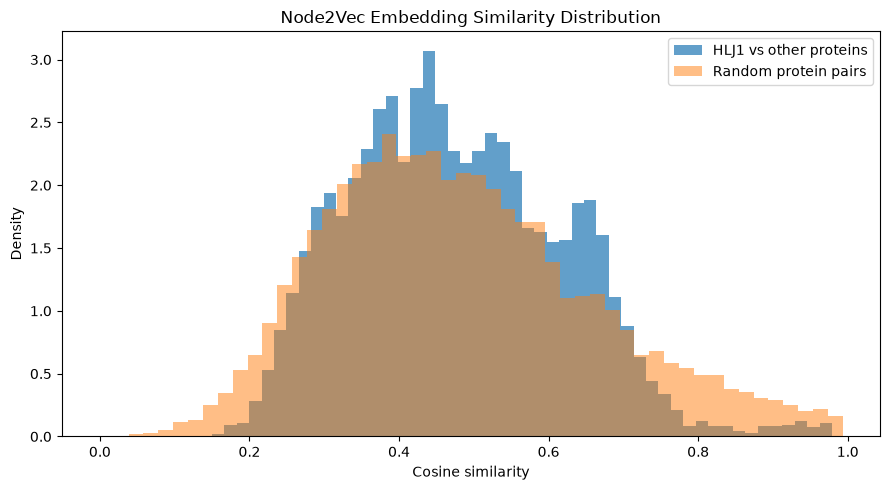

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    hlj1_scores,
    bins=50,
    alpha=0.7,
    density=True,
    label="HLJ1 vs other proteins"
)

ax.hist(
    random_similarities,
    bins=50,
    alpha=0.5,
    density=True,
    label="Random protein pairs"
)

ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Density")
ax.set_title("Node2Vec Embedding Similarity Distribution")

ax.legend()

plt.tight_layout()
plt.show()

In [13]:
# All protein rankings
all_rankings = pd.DataFrame({
    "string_id": nodes,
    "cosine_similarity": hlj1_similarities
})

all_rankings = all_rankings[
    all_rankings["string_id"] != HLJ1_ID
].copy()

all_rankings = (
    all_rankings
    .sort_values(
        "cosine_similarity",
        ascending=False
    )
    .reset_index(drop=True)
)

all_rankings["rank"] = (
    np.arange(len(all_rankings)) + 1
)

all_rankings["orf"] = (
    all_rankings["string_id"]
    .str.replace("4932.", "", regex=False)
)

# Predefined biological references
reference_orfs = (
    set(design["core_seed_orfs"])
    | {"YNL064C", "YJL034W"}
)

reference_orfs.discard("YMR161W")

reference_ranking = all_rankings[
    all_rankings["orf"].isin(reference_orfs)
].copy()

reference_ranking["protein"] = (
    reference_ranking["orf"]
    .map({
        "YNL064C": "YDJ1",
        "YJL034W": "KAR2"
    })
    .fillna(reference_ranking["orf"])
)

reference_ranking = reference_ranking[
    [
        "rank",
        "protein",
        "orf",
        "cosine_similarity"
    ]
]

display(reference_ranking)

,rank,protein,orf,cosine_similarity
17,18,YDJ1,YNL064C,0.945831
87,88,KAR2,YJL034W,0.798503
729,730,YMR264W,YMR264W,0.651947
740,741,YBR201W,YBR201W,0.650752
1336,1337,YOL013C,YOL013C,0.586893
1337,1338,YMR022W,YMR022W,0.586554
1377,1378,YLR207W,YLR207W,0.583001


In [14]:
# Normalised embeddings from the trained model
Z = model.wv.get_normed_vectors()

n = Z.shape[0]

# Mean embedding direction
mu = Z.mean(axis=0)

mean_norm = np.linalg.norm(mu)

# Exact average cosine similarity over distinct node pairs
expected_pair_cosine = (
    n * mean_norm**2 - 1
) / (n - 1)

print(f"Mean embedding norm: {mean_norm:.4f}")
print(f"Mean pairwise cosine: {expected_pair_cosine:.4f}")
print(f"Sampled pairwise cosine: {random_similarities.mean():.4f}")

Mean embedding norm: 0.6916
Mean pairwise cosine: 0.4782
Sampled pairwise cosine: 0.4815


In [15]:
# Shortest-path distances from HLJ1
distances = nx.single_source_shortest_path_length(
    G_hlj1,
    HLJ1_ID
)

# Add graph properties to existing ranking
diagnostic_df = all_rankings.copy()

diagnostic_df["distance"] = (
    diagnostic_df["string_id"].map(distances)
)

diagnostic_df["degree"] = (
    diagnostic_df["string_id"].map(
        dict(G_hlj1.degree())
    )
)

# Rank within each distance group
diagnostic_df["distance_rank"] = (
    diagnostic_df
    .groupby("distance")["cosine_similarity"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Number of proteins at each distance
diagnostic_df["distance_group_size"] = (
    diagnostic_df
    .groupby("distance")["string_id"]
    .transform("size")
)

# Distance-conditioned top percentile
diagnostic_df["distance_top_pct"] = (
    100
    * diagnostic_df["distance_rank"]
    / diagnostic_df["distance_group_size"]
)

# Biological references
reference_orfs = (
    set(design["core_seed_orfs"])
    | {"YNL064C", "YJL034W"}
)

reference_orfs.discard("YMR161W")

reference_results = diagnostic_df[
    diagnostic_df["orf"].isin(reference_orfs)
].copy()

reference_results = reference_results[
    [
        "rank",
        "orf",
        "cosine_similarity",
        "distance",
        "degree",
        "distance_rank",
        "distance_group_size",
        "distance_top_pct"
    ]
]

display(reference_results)

,rank,orf,cosine_similarity,distance,degree,distance_rank,distance_group_size,distance_top_pct
17,18,YNL064C,0.945831,2,67,10,363,2.754821
87,88,YJL034W,0.798503,1,94,23,25,92.000000
729,730,YMR264W,0.651947,2,26,155,363,42.699725
740,741,YBR201W,0.650752,2,22,158,363,43.526171
1336,1337,YOL013C,0.586893,2,36,206,363,56.749311
1337,1338,YMR022W,0.586554,2,24,207,363,57.024793
1377,1378,YLR207W,0.583001,2,22,214,363,58.953168


In [16]:
rwr_scores = nx.pagerank(
    G_hlj1,
    alpha=0.85,
    personalization={HLJ1_ID: 1.0},
    weight="confidence",
    tol=1e-9,
)

# Add RWR scores
diagnostic_df["rwr_score"] = (
    diagnostic_df["string_id"].map(rwr_scores)
)

# RWR rankings
diagnostic_df["rwr_rank"] = (
    diagnostic_df["rwr_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Compare biological references
comparison = diagnostic_df[
    diagnostic_df["orf"].isin(reference_orfs)
][
    [
        "orf",
        "rank",
        "rwr_rank",
        "distance",
        "distance_top_pct"
    ]
].copy()

comparison = comparison.rename(
    columns={
        "rank": "node2vec_rank",
        "distance_top_pct": "n2v_within_distance_top_pct"
    }
)

display(comparison.sort_values("node2vec_rank"))

,orf,node2vec_rank,rwr_rank,distance,n2v_within_distance_top_pct
17,YNL064C,18,24,2,2.754821
87,YJL034W,88,6,1,92.000000
729,YMR264W,730,251,2,42.699725
740,YBR201W,741,176,2,43.526171
1336,YOL013C,1337,118,2,56.749311
1337,YMR022W,1338,286,2,57.024793
1377,YLR207W,1378,182,2,58.953168


In [17]:
# RWR ranking within each shortest-path distance group
diagnostic_df["rwr_distance_rank"] = (
    diagnostic_df
    .groupby("distance")["rwr_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

diagnostic_df["rwr_distance_top_pct"] = (
    100
    * diagnostic_df["rwr_distance_rank"]
    / diagnostic_df["distance_group_size"]
)

# Compare reference proteins
comparison = diagnostic_df[
    diagnostic_df["orf"].isin(reference_orfs)
][
    [
        "orf",
        "distance",
        "rank",
        "rwr_rank",
        "distance_top_pct",
        "rwr_distance_top_pct"
    ]
].copy()

comparison = comparison.rename(columns={
    "rank": "node2vec_rank",
    "distance_top_pct": "n2v_distance_top_pct",
})

display(
    comparison.sort_values("node2vec_rank")
)

,orf,distance,node2vec_rank,rwr_rank,n2v_distance_top_pct,rwr_distance_top_pct
17,YNL064C,2,18,24,2.754821,0.275482
87,YJL034W,1,88,6,92.000000,24.000000
729,YMR264W,2,730,251,42.699725,49.586777
740,YBR201W,2,741,176,43.526171,38.567493
1336,YOL013C,2,1337,118,56.749311,25.068871
1337,YMR022W,2,1338,286,57.024793,55.647383
1377,YLR207W,2,1378,182,58.953168,39.118457


In [18]:
def generate_weighted_walks(
    G,
    num_walks=5,
    walk_length=40,
    seed=3888,
):
    """
    Efficient weighted random walks for p = q = 1.

    Precomputes transition distributions.
    """

    rng = np.random.default_rng(seed)

    nodes = sorted(G.nodes())

    # Precompute transition distributions
    transitions = {}

    for node in nodes:

        neighbors = sorted(G.neighbors(node))

        if not neighbors:
            transitions[node] = ([], None)
            continue

        weights = np.array([
            G[node][nbr]["confidence"]
            for nbr in neighbors
        ], dtype=float)

        probs = weights / weights.sum()
        cumulative = np.cumsum(probs)
        cumulative[-1] = 1.0

        transitions[node] = (
            neighbors,
            cumulative
        )

    walks = []

    for _ in range(num_walks):

        for idx in rng.permutation(len(nodes)):

            start = nodes[idx]

            walk = [start]

            while len(walk) < walk_length:

                current = walk[-1]

                neighbors, cumulative = transitions[current]

                if not neighbors:
                    break

                r = rng.random()

                next_idx = np.searchsorted(
                    cumulative,
                    r,
                    side="right"
                )

                walk.append(neighbors[next_idx])

            walks.append(walk)

    return walks

In [19]:
walks_large = generate_weighted_walks(
    G_hlj1,
    num_walks=5,
    walk_length=40,
    seed=3888
)

print(f"Number of walks: {len(walks_large):,}")
print(f"Total tokens: {sum(map(len, walks_large)):,}")

Number of walks: 28,580
Total tokens: 1,143,200


In [20]:
from gensim.models import Word2Vec

model_large = Word2Vec(
    sentences=walks_large,
    vector_size=64,
    window=5,
    min_count=1,
    sg=1,
    negative=5,
    hs=0,
    sample=0,
    workers=1,
    epochs=5,
    seed=3888,
)

assert len(model_large.wv) == G_hlj1.number_of_nodes()

print("Larger Node2Vec baseline trained successfully!")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Larger Node2Vec baseline trained successfully!


In [21]:
def get_embedding_rankings(model, anchor_id):
    """Return all nodes ranked by cosine similarity."""

    similarities = model.wv.most_similar(
        positive=[anchor_id],
        topn=len(model.wv) - 1
    )

    return {
        protein: rank
        for rank, (protein, _) in enumerate(
            similarities, start=1
        )
    }


small_ranks = get_embedding_rankings(
    model, HLJ1_ID
)

large_ranks = get_embedding_rankings(
    model_large, HLJ1_ID
)

reference_ids = sorted(
    "4932." + orf
    for orf in reference_orfs
)

budget_comparison = pd.DataFrame({
    "protein": reference_ids,
    "small_model_rank": [
        small_ranks[p] for p in reference_ids
    ],
    "large_model_rank": [
        large_ranks[p] for p in reference_ids
    ],
})

budget_comparison["orf"] = (
    budget_comparison["protein"]
    .str.replace("4932.", "", regex=False)
)

budget_comparison["rank_change"] = (
    budget_comparison["small_model_rank"]
    - budget_comparison["large_model_rank"]
)

display(
    budget_comparison[
        [
            "orf",
            "small_model_rank",
            "large_model_rank",
            "rank_change"
        ]
    ].sort_values("small_model_rank")
)

,orf,small_model_rank,large_model_rank,rank_change
5,YNL064C,18,38,-20
1,YJL034W,88,69,19
4,YMR264W,730,150,580
0,YBR201W,741,101,640
6,YOL013C,1337,125,1212
3,YMR022W,1338,215,1123
2,YLR207W,1378,106,1272


In [22]:
# -------------------------------------------
# 1. Extract large-model rankings
# -------------------------------------------

large_similarities = model_large.wv.most_similar(
    positive=[HLJ1_ID],
    topn=len(model_large.wv) - 1
)

large_df = pd.DataFrame(
    large_similarities,
    columns=["string_id", "similarity"]
)

large_df["n2v_rank"] = np.arange(
    1, len(large_df) + 1
)

large_df["orf"] = (
    large_df["string_id"]
    .str.replace("4932.", "", regex=False)
)

# -------------------------------------------
# 2. Add network properties
# -------------------------------------------

large_df["distance"] = (
    large_df["string_id"].map(distances)
)

large_df["degree"] = (
    large_df["string_id"].map(dict(G_hlj1.degree()))
)

large_df["rwr_score"] = (
    large_df["string_id"].map(rwr_scores)
)

large_df["rwr_rank"] = (
    large_df["rwr_score"]
    .rank(method="min", ascending=False)
)

# -------------------------------------------
# 3. Distance-controlled rankings
# -------------------------------------------

large_df["distance_group_size"] = (
    large_df.groupby("distance")["string_id"]
    .transform("size")
)

large_df["n2v_distance_rank"] = (
    large_df.groupby("distance")["similarity"]
    .rank(method="min", ascending=False)
)

large_df["rwr_distance_rank"] = (
    large_df.groupby("distance")["rwr_score"]
    .rank(method="min", ascending=False)
)

large_df["n2v_distance_pct"] = (
    100 * large_df["n2v_distance_rank"]
    / large_df["distance_group_size"]
)

large_df["rwr_distance_pct"] = (
    100 * large_df["rwr_distance_rank"]
    / large_df["distance_group_size"]
)

# -------------------------------------------
# 4. Compare biological references
# -------------------------------------------

reference_results = large_df[
    large_df["orf"].isin(reference_orfs)
].copy()

display(
    reference_results[
        [
            "orf",
            "distance",
            "n2v_rank",
            "rwr_rank",
            "n2v_distance_pct",
            "rwr_distance_pct"
        ]
    ].sort_values("n2v_rank")
)

,orf,distance,n2v_rank,rwr_rank,n2v_distance_pct,rwr_distance_pct
37,YNL064C,2,38,24.0,4.683196,0.275482
68,YJL034W,1,69,6.0,92.000000,24.000000
100,YBR201W,2,101,176.0,17.630854,38.567493
105,YLR207W,2,106,182.0,18.732782,39.118457
124,YOL013C,2,125,118.0,22.865014,25.068871
149,YMR264W,2,150,251.0,25.619835,49.586777
214,YMR022W,2,215,286.0,35.537190,55.647383


In [23]:
from gensim.models import Word2Vec
from itertools import combinations

SEEDS = [3888, 3889, 3890]

all_seed_rankings = {}
all_top20 = {}

for seed in SEEDS:

    print(f"Training seed {seed}...")

    # Reuse the existing model for seed 3888
    if seed == 3888:
        trained_model = model_large

    else:
        walks_seed = generate_weighted_walks(
            G_hlj1,
            num_walks=5,
            walk_length=40,
            seed=seed,
        )

        trained_model = Word2Vec(
            sentences=walks_seed,
            vector_size=64,
            window=5,
            min_count=1,
            sg=1,
            negative=5,
            hs=0,
            sample=0,
            workers=1,
            epochs=5,
            seed=seed,
        )

    # Rank all proteins by HLJ1 similarity
    similarities = trained_model.wv.most_similar(
        positive=[HLJ1_ID],
        topn=len(trained_model.wv) - 1,
    )

    rankings = {
        protein: rank
        for rank, (protein, _) in enumerate(
            similarities,
            start=1,
        )
    }

    all_seed_rankings[seed] = rankings

    all_top20[seed] = {
        protein
        for protein, _ in similarities[:20]
    }

print("All training runs completed!")

Training seed 3888...
Training seed 3889...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training seed 3890...


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


All training runs completed!


In [24]:
rank_matrix = pd.DataFrame(all_seed_rankings)

reference_ids = [
    f"4932.{orf}"
    for orf in sorted(reference_orfs)
]

reference_stability = (
    rank_matrix
    .loc[reference_ids]
    .copy()
)

reference_stability["mean_rank"] = (
    reference_stability[SEEDS].mean(axis=1)
)

reference_stability["std_rank"] = (
    reference_stability[SEEDS].std(axis=1)
)

reference_stability["min_rank"] = (
    reference_stability[SEEDS].min(axis=1)
)

reference_stability["max_rank"] = (
    reference_stability[SEEDS].max(axis=1)
)

reference_stability["orf"] = (
    reference_stability.index
    .str.replace("4932.", "", regex=False)
)

display(
    reference_stability[
        [
            "orf",
            "mean_rank",
            "std_rank",
            "min_rank",
            "max_rank"
        ]
    ].sort_values("mean_rank")
)

,orf,mean_rank,std_rank,min_rank,max_rank
4932.YNL064C,YNL064C,38.333333,3.511885,35,42
4932.YJL034W,YJL034W,66.666667,4.041452,62,69
4932.YLR207W,YLR207W,110.000000,16.370706,96,128
4932.YBR201W,YBR201W,118.333333,50.292478,79,175
4932.YOL013C,YOL013C,133.666667,10.969655,125,146
4932.YMR264W,YMR264W,161.666667,12.013881,150,174
4932.YMR022W,YMR022W,162.666667,52.500794,110,215


In [25]:
overlaps = []

for s1, s2 in combinations(SEEDS, 2):

    A = all_top20[s1]
    B = all_top20[s2]

    intersection = len(A & B)
    union = len(A | B)

    jaccard = intersection / union

    overlaps.append({
        "seed_1": s1,
        "seed_2": s2,
        "intersection": intersection,
        "jaccard": jaccard,
    })

overlap_df = pd.DataFrame(overlaps)

display(overlap_df)

print(
    "Mean Top-20 Jaccard:",
    overlap_df["jaccard"].mean()
)

,seed_1,seed_2,intersection,jaccard
0,3888,3889,17,0.739130
1,3888,3890,16,0.666667
2,3889,3890,16,0.666667


Mean Top-20 Jaccard: 0.6908212560386473


In [26]:
from functools import lru_cache
import numpy as np


def generate_node2vec_walks(
    G,
    num_walks=5,
    walk_length=40,
    p=1.0,
    q=1.0,
    seed=3888,
    max_cached_states=20000,
):
    """
    Generate weighted second-order Node2Vec walks.

    Uses:
    - Precomputed adjacency information
    - Cached transition distributions
    - NumPy random sampling

    Parameters
    ----------
    G : nx.Graph
        Weighted PPI network.
    num_walks : int
        Number of walks starting from each node.
    walk_length : int
        Number of nodes per walk.
    p, q : float
        Node2Vec search-bias parameters.
    seed : int
        Random seed.
    max_cached_states : int
        Maximum number of cached second-order states.

    Returns
    -------
    list[list[str]]
        Random-walk corpus.
    """

    if not np.isfinite(p) or not np.isfinite(q):
        raise ValueError("p and q must be finite.")

    if p <= 0 or q <= 0:
        raise ValueError("p and q must be positive.")

    if num_walks < 1 or walk_length < 1:
        raise ValueError("Invalid walk parameters.")

    rng = np.random.default_rng(seed)

    nodes = sorted(G.nodes())

    # ---------------------------------------
    # 1. Precompute adjacency information
    # ---------------------------------------

    neighbors = {
        u: sorted(G.neighbors(u))
        for u in nodes
    }

    neighbor_sets = {
        u: set(neighbors[u])
        for u in nodes
    }

    weights = {
        u: np.array(
            [
                G[u][v]["confidence"]
                for v in neighbors[u]
            ],
            dtype=float
        )
        for u in nodes
    }

    # ---------------------------------------
    # 2. First-order transition distributions
    # ---------------------------------------

    first_order_cdf = {}

    for u in nodes:

        w = weights[u]

        if len(w) == 0:
            first_order_cdf[u] = None
            continue

        cdf = np.cumsum(w)
        cdf /= cdf[-1]
        cdf[-1] = 1.0

        first_order_cdf[u] = cdf

    # ---------------------------------------
    # 3. Second-order transition distributions
    # ---------------------------------------

    @lru_cache(maxsize=max_cached_states)
    def transition_cdf(previous, current):

        candidates = neighbors[current]

        previous_neighbors = neighbor_sets[previous]

        biases = np.array(
            [
                1.0 / p
                if nxt == previous
                else (
                    1.0
                    if nxt in previous_neighbors
                    else 1.0 / q
                )
                for nxt in candidates
            ],
            dtype=float
        )

        unnormalised = (
            biases * weights[current]
        )

        cdf = np.cumsum(unnormalised)
        cdf /= cdf[-1]
        cdf[-1] = 1.0

        return cdf

    # ---------------------------------------
    # 4. Generate walks
    # ---------------------------------------

    walks = []

    for _ in range(num_walks):

        for idx in rng.permutation(len(nodes)):

            start = nodes[idx]

            walk = [start]

            while len(walk) < walk_length:

                current = walk[-1]

                if len(neighbors[current]) == 0:
                    break

                if len(walk) == 1:
                    cdf = first_order_cdf[current]

                else:
                    previous = walk[-2]

                    cdf = transition_cdf(
                        previous,
                        current
                    )

                j = int(
                    np.searchsorted(
                        cdf,
                        rng.random(),
                        side="right"
                    )
                )

                next_node = neighbors[current][j]

                walk.append(next_node)

            walks.append(walk)

    return walks

In [27]:
test_walks = generate_node2vec_walks(
    G_hlj1,
    num_walks=1,
    walk_length=10,
    p=1,
    q=4,
    seed=3888
)

assert len(test_walks) == 5716

assert all(
    len(walk) == 10
    for walk in test_walks
)

assert all(
    G_hlj1.has_edge(u, v)
    for walk in test_walks
    for u, v in zip(walk[:-1], walk[1:])
)

print("Optimised walk generation passed validation!")

Optimised walk generation passed validation!


In [28]:
from gensim.models import Word2Vec

CONFIGS = {
    "local_q4": (1.0, 4.0),
    "outward_q025": (1.0, 0.25),
}

models = {
    "unbiased": model_large
}

for name, (p, q) in CONFIGS.items():

    print(f"Training {name}: p={p}, q={q}")

    walks_pq = generate_node2vec_walks(
        G_hlj1,
        num_walks=5,
        walk_length=40,
        p=p,
        q=q,
        seed=3888
    )

    model_pq = Word2Vec(
        sentences=walks_pq,
        vector_size=64,
        window=5,
        min_count=1,
        sg=1,
        negative=5,
        hs=0,
        sample=0,
        workers=1,
        epochs=5,
        seed=3888,
    )

    models[name] = model_pq

    del walks_pq

    print(f"Completed: {name}")

print("\nAll configurations trained!")

Training local_q4: p=1.0, q=4.0


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Completed: local_q4
Training outward_q025: p=1.0, q=0.25


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Completed: outward_q025

All configurations trained!


In [29]:
records = []

for name, trained_model in models.items():

    similarities = trained_model.wv.most_similar(
        positive=[HLJ1_ID],
        topn=len(trained_model.wv) - 1
    )

    rank_map = {
        protein: rank
        for rank, (protein, _) in enumerate(
            similarities,
            start=1
        )
    }

    for orf in sorted(reference_orfs):

        protein_id = f"4932.{orf}"

        records.append({
            "configuration": name,
            "orf": orf,
            "rank": rank_map[protein_id],
        })

bias_results = pd.DataFrame(records)

bias_comparison = bias_results.pivot(
    index="orf",
    columns="configuration",
    values="rank"
)

display(bias_comparison)

configuration,local_q4,outward_q025,unbiased
orf,,,
YBR201W,131,161,101
YJL034W,74,44,69
YLR207W,242,196,106
YMR022W,140,272,215
YMR264W,101,297,150
YNL064C,29,28,38
YOL013C,233,173,125


In [30]:
from itertools import combinations

K_VALUES = [20, 50, 100]

# Get complete protein rankings
model_rankings = {}

for name, trained_model in models.items():

    similarities = trained_model.wv.most_similar(
        positive=[HLJ1_ID],
        topn=len(trained_model.wv) - 1
    )

    model_rankings[name] = [
        protein
        for protein, _ in similarities
    ]

# Compare configurations
records = []

for k in K_VALUES:

    for name_a, name_b in combinations(
        model_rankings, 2
    ):

        A = set(model_rankings[name_a][:k])
        B = set(model_rankings[name_b][:k])

        intersection = len(A & B)

        records.append({
            "top_k": k,
            "model_a": name_a,
            "model_b": name_b,
            "intersection": intersection,
            "overlap_fraction": intersection / k,
            "jaccard": intersection / len(A | B),
        })

overlap_comparison = pd.DataFrame(records)

display(overlap_comparison)

,top_k,model_a,model_b,intersection,overlap_fraction,jaccard
0,20,unbiased,local_q4,16,0.80,0.666667
1,20,unbiased,outward_q025,17,0.85,0.739130
2,20,local_q4,outward_q025,16,0.80,0.666667
3,50,unbiased,local_q4,43,0.86,0.754386
4,50,unbiased,outward_q025,42,0.84,0.724138
5,50,local_q4,outward_q025,45,0.90,0.818182
6,100,unbiased,local_q4,87,0.87,0.769912
7,100,unbiased,outward_q025,88,0.88,0.785714
8,100,local_q4,outward_q025,82,0.82,0.694915


In [31]:
from gensim.models import Word2Vec

SEARCH_CONFIGS = {
    "unbiased": (1.0, 1.0),
    "local_q4": (1.0, 4.0),
    "outward_q025": (1.0, 0.25),
}

SEEDS = [3888, 3889, 3890]

experiment_records = []
topk_records = {}

for name, (p, q) in SEARCH_CONFIGS.items():

    for seed in SEEDS:

        print(f"Training {name}, seed={seed}")

        walks = generate_node2vec_walks(
            G_hlj1,
            num_walks=5,
            walk_length=40,
            p=p,
            q=q,
            seed=seed
        )

        trained_model = Word2Vec(
            sentences=walks,
            vector_size=64,
            window=5,
            min_count=1,
            sg=1,
            negative=5,
            hs=0,
            sample=0,
            workers=1,
            epochs=5,
            seed=seed,
        )

        similarities = trained_model.wv.most_similar(
            positive=[HLJ1_ID],
            topn=len(trained_model.wv) - 1
        )

        rank_map = {
            protein: rank
            for rank, (protein, _) in enumerate(
                similarities,
                start=1
            )
        }

        topk_records[(name, seed)] = [
            protein for protein, _ in similarities
        ]

        for orf in sorted(reference_orfs):

            protein_id = f"4932.{orf}"

            experiment_records.append({
                "configuration": name,
                "seed": seed,
                "orf": orf,
                "rank": rank_map[protein_id],
            })

        del walks, trained_model

results = pd.DataFrame(experiment_records)

print("Multi-seed experiment completed!")

Training unbiased, seed=3888


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training unbiased, seed=3889


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training unbiased, seed=3890


...

Training outward_q025, seed=3889


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Training outward_q025, seed=3890


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Multi-seed experiment completed!


In [32]:
summary = (
    results
    .groupby(["configuration", "orf"])
    .agg(
        mean_rank=("rank", "mean"),
        std_rank=("rank", "std"),
        min_rank=("rank", "min"),
        max_rank=("rank", "max"),
    )
    .reset_index()
)

display(summary)

,configuration,orf,mean_rank,std_rank,min_rank,max_rank
0,local_q4,YBR201W,112.000000,19.519221,92,131
1,local_q4,YJL034W,69.666667,11.150486,57,78
2,local_q4,YLR207W,170.000000,65.184354,115,242
3,local_q4,YMR022W,161.000000,19.672316,140,179
4,local_q4,YMR264W,113.666667,22.810816,100,140
5,local_q4,YNL064C,22.333333,11.547005,9,29
6,local_q4,YOL013C,179.666667,48.263167,139,233
7,outward_q025,YBR201W,157.666667,56.074355,100,212
8,outward_q025,YJL034W,45.000000,4.582576,41,50
9,outward_q025,YLR207W,179.666667,19.553346,158,196


In [33]:
from itertools import combinations
import numpy as np
import pandas as pd

CONFIG_NAMES = list(SEARCH_CONFIGS.keys())
K_VALUES = [20, 50, 100]

records = []

def jaccard_at_k(ranking_a, ranking_b, k):
    A = set(ranking_a[:k])
    B = set(ranking_b[:k])

    return len(A & B) / len(A | B)


# ---------------------------------------
# 1. Within-configuration stability
# ---------------------------------------

for config in CONFIG_NAMES:

    for s1, s2 in combinations(SEEDS, 2):

        ranking_a = topk_records[(config, s1)]
        ranking_b = topk_records[(config, s2)]

        for k in K_VALUES:

            records.append({
                "comparison": "within",
                "model_a": config,
                "model_b": config,
                "seed_a": s1,
                "seed_b": s2,
                "top_k": k,
                "jaccard": jaccard_at_k(
                    ranking_a, ranking_b, k
                ),
            })


# ---------------------------------------
# 2. Between-configuration variation
# ---------------------------------------

for seed in SEEDS:

    for config_a, config_b in combinations(
        CONFIG_NAMES, 2
    ):

        ranking_a = topk_records[(config_a, seed)]
        ranking_b = topk_records[(config_b, seed)]

        for k in K_VALUES:

            records.append({
                "comparison": "between",
                "model_a": config_a,
                "model_b": config_b,
                "seed_a": seed,
                "seed_b": seed,
                "top_k": k,
                "jaccard": jaccard_at_k(
                    ranking_a, ranking_b, k
                ),
            })


overlap_df = pd.DataFrame(records)

summary = (
    overlap_df
    .groupby(["comparison", "top_k"])
    .agg(
        mean_jaccard=("jaccard", "mean"),
        std_jaccard=("jaccard", "std"),
        min_jaccard=("jaccard", "min"),
        max_jaccard=("jaccard", "max"),
    )
    .reset_index()
)

display(summary)

,comparison,top_k,mean_jaccard,std_jaccard,min_jaccard,max_jaccard
0,between,20,0.700249,0.064230,0.600000,0.818182
1,between,50,0.812566,0.059170,0.724138,0.923077
2,between,100,0.744925,0.038141,0.694915,0.801802
3,within,20,0.732543,0.059013,0.666667,0.818182
4,within,50,0.804519,0.042655,0.724138,0.851852
5,within,100,0.766705,0.023028,0.724138,0.801802


In [34]:
paired = results.pivot(
    index=["seed", "orf"],
    columns="configuration",
    values="rank"
)

paired["local_minus_unbiased"] = (
    paired["local_q4"]
    - paired["unbiased"]
)

paired["outward_minus_unbiased"] = (
    paired["outward_q025"]
    - paired["unbiased"]
)

paired_summary = (
    paired
    .groupby("orf")[
        [
            "local_minus_unbiased",
            "outward_minus_unbiased"
        ]
    ]
    .agg(["mean", "std", "min", "max"])
)

display(paired_summary)

configuration local_minus_unbiased                     outward_minus_unbiased  \
                              mean        std min  max                   mean   
orf                                                                             
YBR201W                  -6.333333  66.425397 -83   34              39.333333   
YJL034W                   3.000000  14.106736 -12   16             -21.666667   
YLR207W                  60.000000  74.545288 -13  136              69.666667   
YMR022W                  -1.666667  66.289768 -75   54              54.666667   
YMR264W                 -48.000000  26.514147 -74  -21              44.333333   
YNL064C                 -16.000000   8.888194 -26   -9              -8.666667   
YOL013C                  46.000000  54.027771   9  108              15.333333   

configuration                      
                     std min  max  
orf                                
YBR201W        19.604421  21   60  
YJL034W         8.504901 -28  -12  
YLR207W        17.785762  57   90  
YMR022W        12.662280  41   66  
YMR264W        88.934433  -9  147  
YNL064C         6.110101 -14   -2  
YOL013C        54.857391 -48   48

In [35]:
import pandas as pd
import numpy as np

PRIMARY_CONFIG = "unbiased"
SEEDS = [3888, 3889, 3890]

rank_tables = []

for seed in SEEDS:

    ranking = topk_records[(PRIMARY_CONFIG, seed)]

    df = pd.DataFrame({
        "string_id": ranking,
        f"rank_{seed}": np.arange(1, len(ranking) + 1)
    })

    rank_tables.append(
        df.set_index("string_id")
    )

# Combine rankings
consensus_df = pd.concat(
    rank_tables,
    axis=1
)

rank_cols = [
    f"rank_{seed}"
    for seed in SEEDS
]

# Summary statistics
consensus_df["mean_rank"] = (
    consensus_df[rank_cols].mean(axis=1)
)

consensus_df["std_rank"] = (
    consensus_df[rank_cols].std(axis=1)
)

consensus_df["median_rank"] = (
    consensus_df[rank_cols].median(axis=1)
)

# Top-k selection frequency
for k in [20, 50, 100]:

    consensus_df[f"top{k}_frequency"] = (
        consensus_df[rank_cols]
        .le(k)
        .mean(axis=1)
    )

# Add protein information
consensus_df["orf"] = (
    consensus_df.index.to_series()
    .str.replace("4932.", "", regex=False)
)

consensus_df["distance"] = (
    consensus_df.index.map(distances)
)

consensus_df["degree"] = (
    consensus_df.index.map(
        dict(G_hlj1.degree())
    )
)

# Sort by average rank
consensus_df = consensus_df.sort_values(
    "mean_rank"
)

display(
    consensus_df[
        [
            "orf",
            "mean_rank",
            "std_rank",
            "top20_frequency",
            "top50_frequency",
            "top100_frequency",
            "distance",
            "degree"
        ]
    ].head(30)
)

,orf,mean_rank,std_rank,top20_frequency,top50_frequency,top100_frequency,distance,degree
string_id,,,,,,,,
4932.YJL162C,YJL162C,1.000000,0.000000,1.000000,1.0,1.0,2,31
4932.YNL077W,YNL077W,3.666667,2.886751,1.000000,1.0,1.0,2,38
4932.YPL192C,YPL192C,6.333333,4.041452,1.000000,1.0,1.0,3,2
4932.YFR041C,YFR041C,7.333333,3.511885,1.000000,1.0,1.0,1,22
4932.YGL018C,YGL018C,8.000000,5.291503,1.000000,1.0,1.0,1,45
4932.YER048C,YER048C,9.000000,4.000000,1.000000,1.0,1.0,2,11
4932.YFL016C,YFL016C,9.333333,6.506407,1.000000,1.0,1.0,2,40
4932.YIR004W,YIR004W,9.666667,7.637626,1.000000,1.0,1.0,2,10
4932.YPL106C,YPL106C,9.666667,4.163332,1.000000,1.0,1.0,1,51


In [36]:
# Compute RWR rankings on the same node universe
rwr_series = pd.Series(rwr_scores)

rwr_series = rwr_series.drop(
    index=HLJ1_ID
)

rwr_rank = rwr_series.rank(
    method="min",
    ascending=False
)

consensus_df["rwr_rank"] = (
    consensus_df.index.map(rwr_rank)
)

# Difference in global ranks
consensus_df["rank_gap"] = (
    consensus_df["rwr_rank"]
    - consensus_df["mean_rank"]
)

# Exclude predefined biological references
reference_ids = {
    f"4932.{orf}"
    for orf in reference_orfs
}

novel_pool = consensus_df.loc[
    ~consensus_df.index.isin(reference_ids)
].copy()

# Exploratory Node2Vec-specific shortlist
n2v_specific = novel_pool[
    (novel_pool["mean_rank"] <= 100)
    & (novel_pool["top100_frequency"] >= 2 / 3)
    & (novel_pool["rwr_rank"] > 200)
].copy()

display(
    n2v_specific[
        [
            "orf",
            "mean_rank",
            "std_rank",
            "top100_frequency",
            "rwr_rank",
            "rank_gap",
            "distance",
            "degree"
        ]
    ].sort_values("mean_rank")
)

,orf,mean_rank,std_rank,top100_frequency,rwr_rank,rank_gap,distance,degree
string_id,,,,,,,,
4932.YPL192C,YPL192C,6.333333,4.041452,1.000000,833.0,826.666667,3,2
4932.YMR065W,YMR065W,21.000000,11.357817,1.000000,717.0,696.000000,3,3
4932.YLR301W,YLR301W,32.666667,16.258331,1.000000,3266.0,3233.333333,3,1
4932.YLR104W,YLR104W,38.000000,9.539392,1.000000,949.0,911.000000,3,2
4932.YLR256W,YLR256W,44.333333,7.094599,1.000000,1892.0,1847.666667,2,2
4932.YDR143C,YDR143C,53.666667,7.571878,1.000000,387.0,333.333333,2,11
4932.YNL310C,YNL310C,54.000000,11.135529,1.000000,284.0,230.000000,2,10
4932.YOL032W,YOL032W,57.000000,22.338308,1.000000,1070.0,1013.000000,3,4
4932.YCR021C,YCR021C,69.333333,21.126603,1.000000,374.0,304.666667,2,11


In [37]:
# Full HLJ1 component (excluding HLJ1)
network_degree = pd.Series(
    dict(G_hlj1.degree()),
    name="degree"
).drop(index=HLJ1_ID)

# Node2Vec-specific candidates
candidate_degree = n2v_specific["degree"]

degree_summary = pd.DataFrame({
    "network": [
        network_degree.median(),
        network_degree.mean(),
        (network_degree <= 3).mean(),
        (network_degree <= 5).mean(),
    ],
    "n2v_specific": [
        candidate_degree.median(),
        candidate_degree.mean(),
        (candidate_degree <= 3).mean(),
        (candidate_degree <= 5).mean(),
    ],
}, index=[
    "median_degree",
    "mean_degree",
    "fraction_degree_le_3",
    "fraction_degree_le_5",
])

display(degree_summary)

,network,n2v_specific
median_degree,16.000000,7.000000
mean_degree,36.439370,6.652174
fraction_degree_le_3,0.152931,0.434783
fraction_degree_le_5,0.237445,0.478261


In [38]:
controlled_df = consensus_df.copy()

# Add RWR scores
controlled_df["rwr_score"] = (
    controlled_df.index.to_series().map(rwr_scores)
)

# Degree bins
controlled_df["degree_bin"] = pd.cut(
    controlled_df["degree"],
    bins=[0, 2, 5, 10, 20, 50, np.inf],
    labels=[
        "1-2",
        "3-5",
        "6-10",
        "11-20",
        "21-50",
        "51+"
    ]
)

group_cols = ["distance", "degree_bin"]

# Size of each comparison group
controlled_df["stratum_size"] = (
    controlled_df.groupby(
        group_cols,
        observed=True
    )["mean_rank"].transform("size")
)

# Node2Vec rank within matched group
controlled_df["n2v_stratum_rank"] = (
    controlled_df.groupby(
        group_cols,
        observed=True
    )["mean_rank"].rank(
        method="average",
        ascending=True
    )
)

# RWR rank within matched group
controlled_df["rwr_stratum_rank"] = (
    controlled_df.groupby(
        group_cols,
        observed=True
    )["rwr_score"].rank(
        method="average",
        ascending=False
    )
)

# Convert to percentages
controlled_df["n2v_stratum_pct"] = (
    100
    * controlled_df["n2v_stratum_rank"]
    / controlled_df["stratum_size"]
)

controlled_df["rwr_stratum_pct"] = (
    100
    * controlled_df["rwr_stratum_rank"]
    / controlled_df["stratum_size"]
)

# Inspect Node2Vec-specific candidates
controlled_candidates = controlled_df.loc[
    n2v_specific.index
].copy()

display(
    controlled_candidates[
        [
            "orf",
            "mean_rank",
            "rwr_rank",
            "distance",
            "degree",
            "degree_bin",
            "stratum_size",
            "n2v_stratum_pct",
            "rwr_stratum_pct"
        ]
    ].sort_values("mean_rank")
)

,orf,mean_rank,rwr_rank,distance,degree,degree_bin,stratum_size,n2v_stratum_pct,rwr_stratum_pct
string_id,,,,,,,,,
4932.YPL192C,YPL192C,6.333333,833.0,3,2,1-2,43,2.325581,2.325581
4932.YMR065W,YMR065W,21.000000,717.0,3,3,3-5,145,0.689655,0.689655
4932.YLR301W,YLR301W,32.666667,3266.0,3,1,1-2,43,4.651163,18.604651
4932.YLR104W,YLR104W,38.000000,949.0,3,2,1-2,43,6.976744,4.651163
4932.YLR256W,YLR256W,44.333333,1892.0,2,2,1-2,1,100.000000,100.000000
4932.YDR143C,YDR143C,53.666667,387.0,2,11,11-20,48,12.500000,56.250000
4932.YNL310C,YNL310C,54.000000,284.0,2,10,6-10,13,23.076923,38.461538
4932.YOL032W,YOL032W,57.000000,1070.0,3,4,3-5,145,1.379310,1.379310
4932.YCR021C,YCR021C,69.333333,374.0,2,11,11-20,48,20.833333,54.166667


In [39]:
# Number of occurrences in the large baseline corpus
def get_token_count(protein_id):
    return model_large.wv.get_vecattr(
        protein_id,
        "count"
    )


controlled_candidates["walk_token_count"] = [
    get_token_count(pid)
    for pid in controlled_candidates.index
]

display(
    controlled_candidates[
        [
            "orf",
            "mean_rank",
            "degree",
            "distance",
            "walk_token_count",
            "n2v_stratum_pct",
            "rwr_stratum_pct"
        ]
    ].sort_values("mean_rank")
)

,orf,mean_rank,degree,distance,walk_token_count,n2v_stratum_pct,rwr_stratum_pct
string_id,,,,,,,
4932.YPL192C,YPL192C,6.333333,2,3,16,2.325581,2.325581
4932.YMR065W,YMR065W,21.000000,3,3,32,0.689655,0.689655
4932.YLR301W,YLR301W,32.666667,1,3,10,4.651163,18.604651
4932.YLR104W,YLR104W,38.000000,2,3,17,6.976744,4.651163
4932.YLR256W,YLR256W,44.333333,2,2,18,100.000000,100.000000
4932.YDR143C,YDR143C,53.666667,11,2,60,12.500000,56.250000
4932.YNL310C,YNL310C,54.000000,10,2,70,23.076923,38.461538
4932.YOL032W,YOL032W,57.000000,4,3,35,1.379310,1.379310
4932.YCR021C,YCR021C,69.333333,11,2,69,20.833333,54.166667


In [40]:
# --------------------------------------------------
# 1. Load original graph-theoretic features
# --------------------------------------------------

feature_cols = [
    "preferred_name",
    "candidate_eligible",
    "is_core_seed",
    "is_prespecified_readout",
    "community_id",
    "same_community_as_HLJ1",
    "shares_S_community",
    "direct_S_neighbours",
    "jaccard_S_mean",
    "bridge_hS",
    "physical_degree_700",
]

baseline_features = (
    baseline
    .set_index("string_protein_id")[feature_cols]
)

# --------------------------------------------------
# 2. Join Node2Vec diagnostics
# --------------------------------------------------

candidate_panel = controlled_candidates.join(
    baseline_features,
    how="left"
)

assert candidate_panel[
    "candidate_eligible"
].notna().all()

# Respect Notebook 02 eligibility
candidate_panel = candidate_panel[
    candidate_panel["candidate_eligible"]
].copy()

# --------------------------------------------------
# 3. Compute matched ranking disagreement
# --------------------------------------------------

candidate_panel["matched_rank_gap_pp"] = (
    candidate_panel["rwr_stratum_pct"]
    - candidate_panel["n2v_stratum_pct"]
)

# Diagnostic quality flags
candidate_panel["small_stratum"] = (
    candidate_panel["stratum_size"] < 20
)

candidate_panel["low_training_coverage"] = (
    candidate_panel["walk_token_count"] < 50
)

candidate_panel["low_degree"] = (
    candidate_panel["degree"] <= 3
)

# --------------------------------------------------
# 4. Candidate evidence table
# --------------------------------------------------

columns = [
    "orf",
    "preferred_name",
    "mean_rank",
    "std_rank",
    "top100_frequency",
    "rwr_rank",
    "matched_rank_gap_pp",
    "distance",
    "degree",
    "walk_token_count",
    "community_id",
    "same_community_as_HLJ1",
    "shares_S_community",
    "direct_S_neighbours",
    "jaccard_S_mean",
    "physical_degree_700",
    "small_stratum",
    "low_training_coverage",
    "low_degree",
]

candidate_evidence = (
    candidate_panel[columns]
    .sort_values(
        ["small_stratum", "matched_rank_gap_pp"],
        ascending=[True, False]
    )
)

display(candidate_evidence)

,orf,preferred_name,mean_rank,std_rank,top100_frequency,rwr_rank,matched_rank_gap_pp,distance,degree,walk_token_count,community_id,same_community_as_HLJ1,shares_S_community,direct_S_neighbours,jaccard_S_mean,physical_degree_700,small_stratum,low_training_coverage,low_degree
string_id,,,,,,,,,,,,,,,,,,,
4932.YDR143C,YDR143C,SAN1,53.666667,7.571878,1.000000,387.0,43.750000,2,11,60,9,False,True,1,0.069211,0,False,False,False
4932.YCR021C,YCR021C,HSP30,69.333333,21.126603,1.000000,374.0,33.333333,2,11,69,4,True,False,0,0.000000,0,False,False,False
4932.YHR204W,YHR204W,MNL1,99.666667,15.885003,0.666667,459.0,22.916667,2,15,121,9,False,True,3,0.238658,1,False,False,False
4932.YOR057W,YOR057W,SGT1,86.666667,48.757905,0.666667,369.0,20.833333,2,12,80,4,True,False,0,0.000000,4,False,False,False
4932.YKL171W,YKL171W,NNK1,77.666667,54.500765,0.666667,3836.0,18.604651,3,1,10,4,True,False,0,0.000000,0,False,True,True
4932.YBR171W,YBR171W,SEC66,82.333333,11.503623,1.000000,319.0,16.666667,2,14,105,4,True,False,0,0.047794,7,False,False,False
4932.YLR301W,YLR301W,HRI1,32.666667,16.258331,1.000000,3266.0,13.953488,3,1,10,4,True,False,0,0.000000,0,False,True,True
4932.YKL100C,YKL100C,YPF1,80.333333,25.696952,0.666667,3530.0,9.302326,3,1,15,9,False,True,0,0.039763,0,False,True,True
4932.YML029W,YML029W,USA1,88.666667,13.576941,0.666667,262.0,8.333333,2,17,108,9,False,True,5,0.536519,12,False,False,False
